In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

from xgboost import XGBClassifier

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    RandomizedSearchCV,
    cross_val_predict
)

from sklearn.metrics import (
    make_scorer,
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)
from sklearn.model_selection import GridSearchCV


In [3]:
project_root = Path.cwd()
processed_dir = project_root / "data" / "processed"

In [4]:
train_data = pd.read_parquet(
    processed_dir / "train.parquet"
)

test_data = pd.read_parquet(
    processed_dir / "test.parquet"
)

print("Trainingsdaten:", train_data.shape)
print("Testdaten:", test_data.shape)

Trainingsdaten: (160000, 201)
Testdaten: (40000, 201)


In [5]:
X_train = train_data.drop(columns=["target"])
y_train = train_data["target"]

X_test = test_data.drop(columns=["target"])
y_test = test_data["target"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (160000, 200)
y_train: (160000,)
X_test: (40000, 200)
y_test: (40000,)


In [6]:
scoring = {
    "PR_AUC": "average_precision",
    "ROC_AUC": "roc_auc",
    "Precision": make_scorer(
        precision_score,
        zero_division=0
    ),
    "Recall": make_scorer(
        recall_score,
        zero_division=0
    ),
    "F1": make_scorer(
        f1_score,
        zero_division=0
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [7]:
xgb_baseline = XGBClassifier(
    objective="binary:logistic",
    tree_method="hist",
    eval_metric="logloss",
    random_state=42,
    n_jobs=4
)

xgb_baseline

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets im

## XGBoost-Baseline

Das XGBoost-Basismodell wird mittels fünffacher geschichteter Kreuzvalidierung 
auf den Trainingsdaten bewertet. Dabei werden dieselben Folds und Metriken wie 
bei Decision Tree und Random Forest verwendet. Dadurch sind die 
Cross-Validation-Ergebnisse der Modelle direkt vergleichbar.

In [8]:
xgb_baseline_results = cross_validate(
    xgb_baseline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=4,
    return_train_score=True
)

In [9]:
for metric in scoring:
    train_scores = xgb_baseline_results[f"train_{metric}"]
    validation_scores = xgb_baseline_results[f"test_{metric}"]

    print(
        f"{metric}:\n"
        f"  Training:    {train_scores.mean():.4f} "
        f"(± {train_scores.std():.4f})\n"
        f"  Validierung: {validation_scores.mean():.4f} "
        f"(± {validation_scores.std():.4f})"
    )

print(
    "\nMittlere Trainingszeit pro Fold: "
    f"{xgb_baseline_results['fit_time'].mean():.2f} Sekunden"
)

PR_AUC:
  Training:    0.9440 (± 0.0013)
  Validierung: 0.4872 (± 0.0092)
ROC_AUC:
  Training:    0.9873 (± 0.0004)
  Validierung: 0.8557 (± 0.0029)
Precision:
  Training:    0.9887 (± 0.0011)
  Validierung: 0.6740 (± 0.0193)
Recall:
  Training:    0.6679 (± 0.0026)
  Validierung: 0.2495 (± 0.0054)
F1:
  Training:    0.7973 (± 0.0021)
  Validierung: 0.3641 (± 0.0083)

Mittlere Trainingszeit pro Fold: 62.70 Sekunden


**Ergebnis der XGBoost-Baseline:** Das Basismodell erreicht eine mittlere 
Validierungs-PR-AUC von 0,487 und eine ROC-AUC von 0,856. Damit liegt es knapp 
vor dem bisher besten Random-Forest-Modell. Die deutlich höhere Trainings-PR-AUC 
von 0,944 weist jedoch auf Overfitting hin. Durch eine gezielte Regulierung der 
Baumtiefe, Lernrate, Stichprobenanteile und Regularisierungsparameter soll die 
Generalisierungsfähigkeit im nächsten Schritt verbessert werden.

In [10]:
xgb_baseline_scores = pd.DataFrame({
    "Modell": "XGBoost_Baseline",
    "Fold": range(1, 6),
    "PR_AUC": xgb_baseline_results["test_PR_AUC"],
    "ROC_AUC": xgb_baseline_results["test_ROC_AUC"],
    "Precision": xgb_baseline_results["test_Precision"],
    "Recall": xgb_baseline_results["test_Recall"],
    "F1": xgb_baseline_results["test_F1"],
    "Fit_Time": xgb_baseline_results["fit_time"],
    "Schwellenwert": 0.5
})

results_dir = project_root / "results" / "cv"
results_dir.mkdir(parents=True, exist_ok=True)

xgb_baseline_scores.to_csv(
    results_dir / "xgboost_baseline_cv.csv",
    index=False
)

In [11]:
X_split, _, y_split, _ = train_test_split(
    X_train,
    y_train,
    train_size=60_000,
    stratify=y_train,
    random_state=42
)

print("X_tune:", X_split.shape)
print("Klassenanteile:")
print(y_split.value_counts(normalize=True))

X_tune: (60000, 200)
Klassenanteile:
target
0    0.899517
1    0.100483
Name: proportion, dtype: float64


In [12]:
class_ratio = (
    (y_split == 0).sum()
    / (y_split == 1).sum()
)

print("Klassenverhältnis:", round(class_ratio, 3))

Klassenverhältnis: 8.952


In [13]:
xgb_parameter_space = {
    "n_estimators": [
        100, 200, 400, 600
    ],
    "learning_rate": [
        0.02, 0.05, 0.10, 0.20
    ],
    "max_depth": [
        2, 3, 4, 5, 6, 8
    ],
    "min_child_weight": [
        1, 3, 5, 10, 20
    ],
    "subsample": [
        0.6, 0.8, 1.0
    ],
    "colsample_bytree": [
        0.5, 0.7, 0.9, 1.0
    ],
    "gamma": [
        0, 0.1, 0.5, 1.0
    ],
    "reg_alpha": [
        0, 0.01, 0.1, 1.0
    ],
    "reg_lambda": [
        1, 3, 5, 10
    ],
    "scale_pos_weight": [
        1.0,
        class_ratio / 2,
        class_ratio
    ]
}

In [14]:
tuning_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [15]:
xgb_search = RandomizedSearchCV(
    estimator=XGBClassifier(
        objective="binary:logistic",
        tree_method="hist",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ),
    param_distributions=xgb_parameter_space,
    n_iter=20,
    scoring="average_precision",
    cv=tuning_cv,
    n_jobs=4,
    random_state=42,
    return_train_score=True,
    verbose=2
)

xgb_search.fit(
    X_split,
    y_split
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END colsample_bytree=0.5, gamma=0.1, learning_rate=0.2, max_depth=2, min_child_weight=3, n_estimators=400, reg_alpha=1.0, reg_lambda=5, scale_pos_weight=8.951899154088572, subsample=1.0; total time=  28.5s
[CV] END colsample_bytree=0.5, gamma=0.1, learning_rate=0.2, max_depth=2, min_child_weight=3, n_estimators=400, reg_alpha=1.0, reg_lambda=5, scale_pos_weight=8.951899154088572, subsample=1.0; total time=  28.9s
[CV] END colsample_bytree=0.5, gamma=0.1, learning_rate=0.2, max_depth=2, min_child_weight=3, n_estimators=400, reg_alpha=1.0, reg_lambda=5, scale_pos_weight=8.951899154088572, subsample=1.0; total time=  29.1s
[CV] END colsample_bytree=0.5, gamma=0.1, learning_rate=0.2, max_depth=2, min_child_weight=3, n_estimators=400, reg_alpha=1.0, reg_lambda=5, scale_pos_weight=8.951899154088572, subsample=1.0; total time=  29.5s
[CV] END colsample_bytree=0.5, gamma=0.1, learning_rate=0.2, max_depth=2, min_child_weight=3, 

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.5, 0.7, ...], 'gamma': [0, 0.1, ...], 'learning_rate': [0.02, 0.05, ...], 'max_depth': [2, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be us

In [16]:
xgb_search_results = pd.DataFrame(
    xgb_search.cv_results_
)

xgb_search_results["overfit_gap"] = (
    xgb_search_results["mean_train_score"]
    - xgb_search_results["mean_test_score"]
)

result_columns = [
    "rank_test_score",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "overfit_gap",
    "param_n_estimators",
    "param_learning_rate",
    "param_max_depth",
    "param_min_child_weight",
    "param_subsample",
    "param_colsample_bytree",
    "param_scale_pos_weight",
    "param_gamma",
    "param_reg_alpha",
    "param_reg_lambda",
    "mean_fit_time"
]

all_xgb_results = (
    xgb_search_results[result_columns]
    .sort_values("rank_test_score")
    .reset_index(drop=True)
)

all_xgb_results

,rank_test_score,mean_train_score,mean_test_score,std_test_score,overfit_gap,param_n_estimators,param_learning_rate,param_max_depth,param_min_child_weight,param_subsample,param_colsample_bytree,param_scale_pos_weight,param_gamma,param_reg_alpha,param_reg_lambda,mean_fit_time
0,1,0.786530,0.571625,0.008453,0.214906,600,0.20,2,3,0.8,0.7,1.000000,0.0,0.01,1,35.909403
1,2,0.716704,0.551654,0.010232,0.165051,400,0.20,2,3,1.0,0.5,8.951899,0.1,1.00,5,28.532676
2,3,0.762902,0.550787,0.009631,0.212115,600,0.05,3,5,0.6,1.0,4.475950,0.5,0.00,3,36.602670
3,4,0.999815,0.540845,0.008737,0.458969,600,0.10,6,1,0.6,0.5,1.000000,0.5,0.00,10,82.468223
4,5,1.000000,0.537533,0.008311,0.462467,600,0.10,8,20,1.0,0.5,4.475950,1.0,1.00,3,122.062056
5,6,1.000000,0.536047,0.003738,0.463953,600,0.10,8,5,0.6,0.7,1.000000,0.0,0.01,3,138.102424
6,7,0.981078,0.534365,0.011986,0.446713,400,0.05,6,20,0.8,0.9,4.475950,1.0,0.00,10,76.077214
7,8,0.946270,0.526314,0.010084,0.419956,400,0.05,5,3,0.8,0.9,8.951899,1.0,0.10,5,59.876536
8,9,0.812507,0.519478,0.011702,0.293030,200,0.10,4,3,0.6,0.5,1.000000,0.1,1.00,1,25.341258
9,10,0.825802,0.513714,0.007607,0.312088,200,0.10,4,3,1.0,0.5,4.475950,0.0,0.01,3,20.724853


In [17]:
round2_fixed_params = xgb_search.best_params_.copy()

round2_fixed_params.pop("n_estimators")
round2_fixed_params.pop("learning_rate")

round2_fixed_params

{'subsample': 0.8,
 'scale_pos_weight': 1.0,
 'reg_lambda': 1,
 'reg_alpha': 0.01,
 'min_child_weight': 3,
 'max_depth': 2,
 'gamma': 0,
 'colsample_bytree': 0.7}

In [18]:
xgb_round2_model = XGBClassifier(
    objective="binary:logistic",
    tree_method="hist",
    eval_metric="logloss",
    random_state=42,
    n_jobs=1,
    **round2_fixed_params
)

In [19]:
round2_parameter_grid = {
    "n_estimators": [
        400, 600, 800, 1000, 1500
    ],
    "learning_rate": [
        0.03, 0.05, 0.10, 0.15, 0.20, 0.25
    ]
}

In [20]:
xgb_grid_round2 = GridSearchCV(
    estimator=xgb_round2_model,
    param_grid=round2_parameter_grid,
    scoring="average_precision",
    cv=tuning_cv,
    n_jobs=4,
    return_train_score=True,
    verbose=2
)

xgb_grid_round2.fit(
    X_split,
    y_split
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
[CV] END ...............learning_rate=0.03, n_estimators=400; total time=  20.5s
[CV] END ...............learning_rate=0.03, n_estimators=400; total time=  20.6s
[CV] END ...............learning_rate=0.03, n_estimators=400; total time=  21.0s
[CV] END ...............learning_rate=0.03, n_estimators=400; total time=  21.0s
[CV] END ...............learning_rate=0.03, n_estimators=400; total time=  20.4s
[CV] END ...............learning_rate=0.03, n_estimators=600; total time=  29.1s
[CV] END ...............learning_rate=0.03, n_estimators=600; total time=  29.1s
[CV] END ...............learning_rate=0.03, n_estimators=600; total time=  29.1s
[CV] END ...............learning_rate=0.03, n_estimators=600; total time=  29.6s
[CV] END ...............learning_rate=0.03, n_estimators=600; total time=  30.3s
[CV] END ...............learning_rate=0.03, n_estimators=800; total time=  40.0s
[CV] END ...............learning_rate=0.03, n_e

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.03, 0.05, ...], 'n_estimators': [400, 600, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidat

In [21]:
print(
    "Beste mittlere PR-AUC:",
    f"{xgb_grid_round2.best_score_:.4f}"
)

print("\nBeste Parameter:")
xgb_grid_round2.best_params_

Beste mittlere PR-AUC: 0.5829

Beste Parameter:


{'learning_rate': 0.1, 'n_estimators': 1500}

In [22]:
round2_results = pd.DataFrame(
    xgb_grid_round2.cv_results_
)

round2_results["overfit_gap"] = (
    round2_results["mean_train_score"]
    - round2_results["mean_test_score"]
)

round2_table = (
    round2_results[
        [
            "rank_test_score",
            "mean_train_score",
            "mean_test_score",
            "std_test_score",
            "overfit_gap",
            "param_n_estimators",
            "param_learning_rate",
            "mean_fit_time"
        ]
    ]
    .sort_values("rank_test_score")
    .reset_index(drop=True)
)

round2_table

,rank_test_score,mean_train_score,mean_test_score,std_test_score,overfit_gap,param_n_estimators,param_learning_rate,mean_fit_time
0,1,0.824043,0.582931,0.009419,0.241112,1500,0.10,76.373793
1,2,0.780728,0.579734,0.008359,0.200995,1000,0.10,52.371827
2,3,0.817551,0.576612,0.009413,0.240939,1000,0.15,52.354863
3,4,0.792926,0.575340,0.009534,0.217586,800,0.15,43.059974
4,5,0.757356,0.574297,0.009275,0.183059,1500,0.05,75.236671
5,6,0.869792,0.574087,0.011817,0.295705,1500,0.15,75.903116
6,7,0.819924,0.571766,0.008619,0.248158,800,0.20,42.544303
7,8,0.758329,0.571736,0.008034,0.186593,800,0.10,42.549283
8,9,0.786530,0.571625,0.008453,0.214906,600,0.20,33.345121
9,10,0.762715,0.571195,0.008695,0.191520,600,0.15,33.022223


In [23]:
tuning_dir = project_root / "results" / "tuning"

tuning_dir.mkdir(
    parents=True,
    exist_ok=True
)

In [24]:
round2_results.to_csv(
    tuning_dir / "xgboost_grid_search_round2_full.csv",
    index=False
)

In [25]:
round2_pivot = round2_results.pivot(
    index="param_learning_rate",
    columns="param_n_estimators",
    values="mean_test_score"
)

round2_pivot.round(4)

param_n_estimators,400,600,800,1000,1500
param_learning_rate,,,,,
0.03,0.4485,0.4834,0.5079,0.5269,0.5545
0.05,0.4879,0.5208,0.5417,0.5570,0.5743
0.10,0.5402,0.5611,0.5717,0.5797,0.5829
0.15,0.5551,0.5712,0.5753,0.5766,0.5741
0.20,0.5609,0.5716,0.5718,0.5703,0.5621
0.25,0.5589,0.5649,0.5630,0.5605,0.5496


**Ergebnis der zweiten Hyperparametersuche:** Die gemeinsame Untersuchung von 
Lernrate und Baumanzahl zeigt die für Gradient Boosting typische Gegenbeziehung: 
Bei höheren Lernraten wird das Leistungsmaximum bereits mit weniger Bäumen 
erreicht, während kleinere Lernraten mehr Boosting-Runden benötigen. Die höchste 
mittlere PR-AUC von 0,583 wird mit einer Lernrate von 0,10 und 1.500 Bäumen 
erreicht. Gegenüber 1.000 Bäumen beträgt die Verbesserung jedoch nur rund 0,003, 
während Trainingszeit und Overfitting zunehmen. Daher werden beide Konfigurationen 
auf dem vollständigen Trainingsdatensatz verglichen.

In [26]:
round2_table.to_csv(
    tuning_dir / "xgboost_grid_search_round2.csv",
    index=False
)

In [27]:
xgb_candidate_1000 = XGBClassifier(
    objective="binary:logistic",
    tree_method="hist",
    eval_metric="logloss",
    random_state=42,
    n_jobs=4,
    **round2_fixed_params,
    n_estimators=1000,
    learning_rate=0.10
)

xgb_candidate_1500 = XGBClassifier(
    objective="binary:logistic",
    tree_method="hist",
    eval_metric="logloss",
    random_state=42,
    n_jobs=4,
    **round2_fixed_params,
    n_estimators=1500,
    learning_rate=0.10
)

In [28]:
xgb_finalists = {
    "XGBoost_1000": xgb_candidate_1000,
    "XGBoost_1500": xgb_candidate_1500
}

xgb_finalist_results = {}

for model_name, model in xgb_finalists.items():
    print("Trainiere:", model_name)

    xgb_finalist_results[model_name] = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=True
    )

Trainiere: XGBoost_1000
Trainiere: XGBoost_1500


In [29]:
summary_rows = []

for model_name, results in xgb_finalist_results.items():
    row = {
        "Modell": model_name,
        "Train_PR_AUC": results["train_PR_AUC"].mean(),
        "PR_AUC": results["test_PR_AUC"].mean(),
        "PR_AUC_std": results["test_PR_AUC"].std(),
        "ROC_AUC": results["test_ROC_AUC"].mean(),
        "ROC_AUC_std": results["test_ROC_AUC"].std(),
        "Precision": results["test_Precision"].mean(),
        "Recall": results["test_Recall"].mean(),
        "F1": results["test_F1"].mean(),
        "Fit_Time": results["fit_time"].mean()
    }

    row["Overfit_Gap"] = (
        row["Train_PR_AUC"] - row["PR_AUC"]
    )

    summary_rows.append(row)

xgb_finalist_summary = pd.DataFrame(
    summary_rows
).set_index("Modell")

xgb_finalist_summary.round(4)

,Train_PR_AUC,PR_AUC,PR_AUC_std,ROC_AUC,ROC_AUC_std,Precision,Recall,F1,Fit_Time,Overfit_Gap
Modell,,,,,,,,,,
XGBoost_1000,0.6945,0.5955,0.0106,0.8924,0.0032,0.8006,0.2813,0.4162,36.5974,0.0990
XGBoost_1500,0.7208,0.6049,0.0104,0.8955,0.0031,0.7717,0.3365,0.4686,52.7013,0.1158


In [30]:
pr_auc_comparison = pd.DataFrame({
    "Fold": range(1, 6),
    "XGBoost_1000": (
        xgb_finalist_results["XGBoost_1000"]["test_PR_AUC"]
    ),
    "XGBoost_1500": (
        xgb_finalist_results["XGBoost_1500"]["test_PR_AUC"]
    )
})

pr_auc_comparison["Differenz_1500_minus_1000"] = (
    pr_auc_comparison["XGBoost_1500"]
    - pr_auc_comparison["XGBoost_1000"]
)

pr_auc_comparison.round(4)

,Fold,XGBoost_1000,XGBoost_1500,Differenz_1500_minus_1000
0,1,0.5921,0.6020,0.0099
1,2,0.5914,0.6006,0.0092
2,3,0.6150,0.6239,0.0089
3,4,0.5833,0.5926,0.0093
4,5,0.5958,0.6057,0.0099


In [31]:
xgb_finalist_fold_results = []

for model_name, results in xgb_finalist_results.items():
    model_scores = pd.DataFrame({
        "Modell": model_name,
        "Fold": range(1, 6),
        "PR_AUC": results["test_PR_AUC"],
        "ROC_AUC": results["test_ROC_AUC"],
        "Precision": results["test_Precision"],
        "Recall": results["test_Recall"],
        "F1": results["test_F1"],
        "Fit_Time": results["fit_time"],
        "Schwellenwert": 0.5
    })

    xgb_finalist_fold_results.append(model_scores)

xgb_finalist_fold_results = pd.concat(
    xgb_finalist_fold_results,
    ignore_index=True
)

xgb_finalist_fold_results.to_csv(
    results_dir / "xgboost_finalists_cv.csv",
    index=False
)

# Bestimmung des Schwellenwerts

In [32]:
oof_probabilities = cross_val_predict(
    xgb_candidate_1500,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

print("Anzahl OOF-Wahrscheinlichkeiten:", len(oof_probabilities))

Anzahl OOF-Wahrscheinlichkeiten: 160000


In [33]:
thresholds = np.arange(0.05, 0.51, 0.01)

threshold_rows = []

for threshold in thresholds:
    oof_predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train,
            oof_predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_train,
            oof_predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_train,
            oof_predictions,
            zero_division=0
        ),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_train,
            oof_predictions
        )
    })

threshold_results = pd.DataFrame(threshold_rows)

threshold_results.sort_values(
    "F1",
    ascending=False
).head(10).round(4)

,Threshold,Precision,Recall,F1,Balanced_Accuracy
19,0.24,0.5374,0.5961,0.5652,0.7694
20,0.25,0.5485,0.5828,0.5651,0.7646
18,0.23,0.5256,0.6102,0.5647,0.7743
17,0.22,0.5140,0.6252,0.5642,0.7796
22,0.27,0.5705,0.5578,0.5641,0.7555
21,0.26,0.5591,0.5684,0.5637,0.7591
23,0.28,0.5810,0.5458,0.5629,0.7509
24,0.29,0.5919,0.5346,0.5618,0.7467
16,0.21,0.4993,0.6368,0.5597,0.7827
25,0.30,0.6011,0.5234,0.5596,0.7423


In [43]:
# Gewünschte Schwellenwerte auswählen
selected_thresholds = [0.10, 0.20, 0.24, 0.30, 0.50]

# Ergebnisse filtern und anzeigen
threshold_results[
    threshold_results["Threshold"].round(2).isin(selected_thresholds)
].round(3)

,Threshold,Precision,Recall,F1,Balanced_Accuracy
5,0.10,0.327,0.814,0.467,0.813
15,0.20,0.486,0.650,0.556,0.786
19,0.24,0.537,0.596,0.565,0.769
25,0.30,0.601,0.523,0.560,0.742
45,0.50,0.772,0.336,0.469,0.663


**Ergebnis der Schwellenwertanalyse:**  
Auf Grundlage der Out-of-Fold-Wahrscheinlichkeiten erreicht das
XGBoost-Modell bei einem Schwellenwert von 0,24 den höchsten F1-Score
von rund 0,565. Dabei werden eine Precision von etwa 0,537 und ein
Recall von etwa 0,596 erreicht. Die benachbarten Schwellenwerte zwischen
0,23 und 0,25 liefern sehr ähnliche Ergebnisse, sodass die Auswahl nicht
von einem einzelnen instabilen Schwellenwert abhängt. Für die finale
Klassifikation wird daher ein Schwellenwert von 0,24 festgelegt.

## Finales Training und Testevaluation

Nach der Auswahl von `XGBoost_1500` und der Bestimmung des
F1-optimierten Schwellenwertes wird das Modell neu auf dem gesamten
Trainingsdatensatz trainiert. Für die finale Klassifikation wird der
zuvor festgelegte Schwellenwert von 0,24 verwendet.

In [35]:
FINAL_THRESHOLD = 0.24

final_xgb_model = XGBClassifier(
    **xgb_candidate_1500.get_params()
)

final_xgb_model.fit(
    X_train,
    y_train
)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.7
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets imp

In [36]:
y_test_proba = final_xgb_model.predict_proba(
    X_test
)[:, 1]

y_test_pred = (
    y_test_proba >= FINAL_THRESHOLD
).astype(int)

test_results = pd.DataFrame({
    "Modell": ["XGBoost_1500"],

    "PR_AUC": [
        average_precision_score(
            y_test,
            y_test_proba
        )
    ],

    "ROC_AUC": [
        roc_auc_score(
            y_test,
            y_test_proba
        )
    ],

    "Balanced_Accuracy": [
        balanced_accuracy_score(
            y_test,
            y_test_pred
        )
    ],

    "Precision": [
        precision_score(
            y_test,
            y_test_pred,
            zero_division=0
        )
    ],

    "Recall": [
        recall_score(
            y_test,
            y_test_pred,
            zero_division=0
        )
    ],

    "F1": [
        f1_score(
            y_test,
            y_test_pred,
            zero_division=0
        )
    ],

    "Schwellenwert": [FINAL_THRESHOLD]
})

test_results.round(4)

,Modell,PR_AUC,ROC_AUC,Balanced_Accuracy,Precision,Recall,F1,Schwellenwert
0,XGBoost_1500,0.6002,0.8959,0.7664,0.537,0.5896,0.5621,0.24


In [37]:
test_results_dir = project_root / "results" / "test"
test_results_dir.mkdir(parents=True, exist_ok=True)

test_results.to_csv(
    test_results_dir / "xgboost_final_test.csv",
    index=False
)

threshold_results.to_csv(
    test_results_dir / "xgboost_threshold_analysis.csv",
    index=False
)

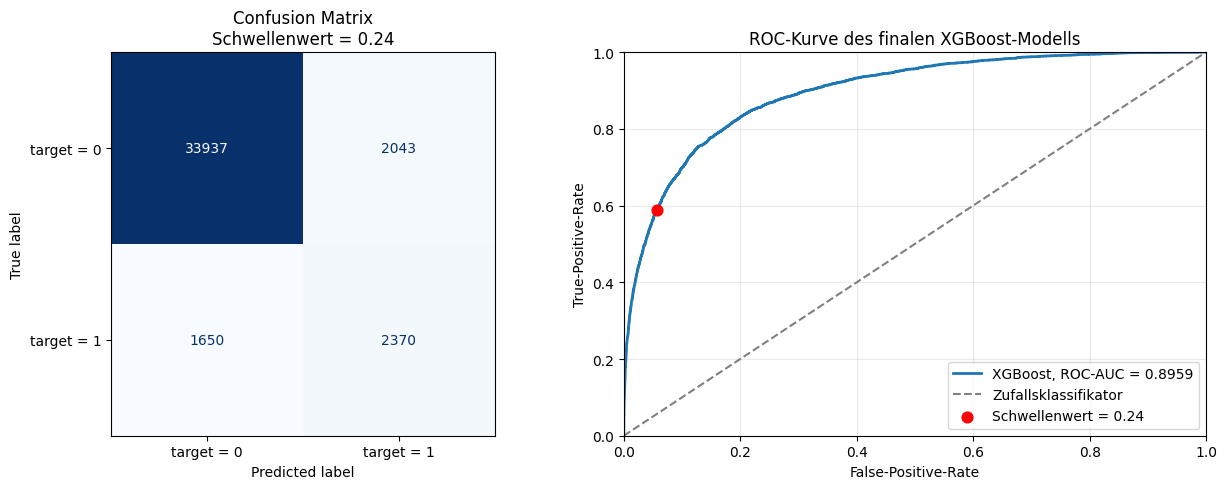

In [38]:
# Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_test_pred
)

# ROC-Kurve
fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    y_test_proba
)

test_roc_auc = roc_auc_score(
    y_test,
    y_test_proba
)

# Punkt der gewählten Schwelle auf der ROC-Kurve
threshold_index = np.argmin(
    np.abs(roc_thresholds - FINAL_THRESHOLD)
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

# Confusion Matrix darstellen
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["target = 0", "target = 1"]
)

cm_display.plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[0].set_title(
    f"Confusion Matrix\nSchwellenwert = {FINAL_THRESHOLD:.2f}"
)

# ROC-Kurve darstellen
axes[1].plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"XGBoost, ROC-AUC = {test_roc_auc:.4f}"
)

axes[1].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Zufallsklassifikator"
)

axes[1].scatter(
    fpr[threshold_index],
    tpr[threshold_index],
    color="red",
    s=60,
    zorder=3,
    label=f"Schwellenwert = {FINAL_THRESHOLD:.2f}"
)

axes[1].set_title("ROC-Kurve des finalen XGBoost-Modells")
axes[1].set_xlabel("False-Positive-Rate")
axes[1].set_ylabel("True-Positive-Rate")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].grid(alpha=0.25)
axes[1].legend()

plt.tight_layout()
plt.show()

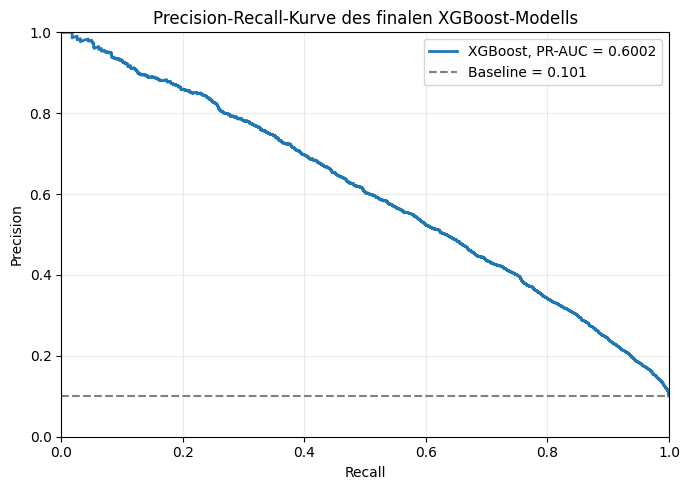

In [39]:
precision_curve, recall_curve, _ = precision_recall_curve(
    y_test,
    y_test_proba
)

test_pr_auc = average_precision_score(
    y_test,
    y_test_proba
)

positive_share = y_test.mean()

plt.figure(figsize=(7, 5))

plt.plot(
    recall_curve,
    precision_curve,
    linewidth=2,
    label=f"XGBoost, PR-AUC = {test_pr_auc:.4f}"
)

plt.axhline(
    positive_share,
    linestyle="--",
    color="gray",
    label=f"Baseline = {positive_share:.3f}"
)

plt.title("Precision-Recall-Kurve des finalen XGBoost-Modells")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()

## Ergebnis der finalen Testevaluation

Das ausgewählte XGBoost-Modell wurde auf dem vollständigen Trainingsdatensatz trainiert. Für die Klassifikation wurde der zuvor anhand der Out-of-Fold-Vorhersagen bestimmte Schwellenwert von 0,24 verwendet.

Auf dem unabhängigen Testdatensatz erreicht das Modell eine PR-AUC von 0,600, eine ROC-AUC von 0,896 und eine Balanced Accuracy von 0,766. Precision, Recall und F1-Score betragen 0,537, 0,590 und 0,562.

Die Confusion Matrix zeigt 33.937 korrekt erkannte negative und 2.370 korrekt erkannte positive Beobachtungen. Demgegenüber stehen 2.043 falsch-positive und 1.650 falsch-negative Klassifikationen. Das Modell erkennt damit rund 59 % der tatsächlich positiven Fälle, während etwa 5,7 % der negativen Fälle fälschlich als positiv eingestuft werden.

Die ROC-Kurve liegt deutlich oberhalb der Zufallsdiagonalen und bestätigt die gute Trennfähigkeit des Modells. Auch die PR-AUC von 0,600 liegt klar über der durch den positiven Klassenanteil bestimmten Baseline von ungefähr 0,101. Die Precision-Recall-Kurve verdeutlicht dabei den üblichen Zielkonflikt zwischen der Erkennung möglichst vieler positiver Fälle und der Vermeidung falsch-positiver Vorhersagen.

Da die Testergebnisse sehr nahe an den vorherigen Kreuzvalidierungs- und Out-of-Fold-Ergebnissen liegen, kann von einer stabilen Generalisierung auf unbekannte Beobachtungen ausgegangen werden.

